In [1]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install numpy


Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import json

quantized_dir = Path("benchmarks/results_quantized/raw")

results_file = Path("benchmarks/results/raw/meta-llama_Llama-3.1-8B.json")

print("Current working directory:", Path.cwd())
print("Baseline path:", results_file.resolve())

# Check what's actually in the folder first
quantized_files = sorted(quantized_dir.glob("*.json"))
print("Quantized files found:", [p.name for p in quantized_files])

# Pick each file by a keyword in its name
awq_path = next(p for p in quantized_files if "awq" in p.name.lower())
rtn_path = next(p for p in quantized_files if "rtn" in p.name.lower())
nf4_path = next(p for p in quantized_files if "nf4" in p.name.lower())

awq_result = json.loads(awq_path.read_text())
rtn_result = json.loads(rtn_path.read_text())
nf4_result = json.loads(nf4_path.read_text())
baseline_result = json.loads(results_file.read_text())


print(f"Loaded AWQ:      {awq_path.name}")
print(f"Loaded RTN:      {rtn_path.name}")
print(f"Loaded NF4:      {nf4_path.name}")
print(f"Loaded baseline: {results_file.name}")

Current working directory: /users/cp2025/cp2025_001/tesis/Tesis
Baseline path: /users/cp2025/cp2025_001/tesis/Tesis/benchmarks/results/raw/meta-llama_Llama-3.1-8B.json
Quantized files found: ['_users_cp2025_cp2025_001_tesis_Tesis_test_methods_quantized_Llama-3.1-8B-awq.json', '_users_cp2025_cp2025_001_tesis_Tesis_test_methods_quantized_Llama-3.1-8B-rtn.json', 'pretrained_meta-llama_Llama-3.1-8B_load_in_4bit_True_bnb_4bit_quant_type_nf4_bnb_4bit_use_double_quant_True.json']
Loaded AWQ:      _users_cp2025_cp2025_001_tesis_Tesis_test_methods_quantized_Llama-3.1-8B-awq.json
Loaded RTN:      _users_cp2025_cp2025_001_tesis_Tesis_test_methods_quantized_Llama-3.1-8B-rtn.json
Loaded NF4:      pretrained_meta-llama_Llama-3.1-8B_load_in_4bit_True_bnb_4bit_quant_type_nf4_bnb_4bit_use_double_quant_True.json
Loaded baseline: meta-llama_Llama-3.1-8B.json


In [5]:
def benchmarks_results(file):
    data = json.loads(Path(file).read_text())

    benchmarks = {}
    for row in data["rows"]:
        task = row["task"]
        bench = benchmarks.setdefault(task, {
            "acc": None,
            "n_samples": row["n_samples"],
            "total_time_s": row["total_time_s"],
            "metrics": {},
        })
        if row["metric"] == "sample_len":  # just a counter, not a real metric
            continue
        bench["metrics"][row["metric"]] = row["value"]

    # "acc" is None for tasks that don't report it (e.g. sqac)
    for bench in benchmarks.values():
        bench["acc"] = bench["metrics"].get("acc")

    return {
        "name": Path(data["perf"]["model"]).name,
        "benchmarks": benchmarks,
    }

awq = benchmarks_results(awq_path)
rtn = benchmarks_results(rtn_path)
nf4 = benchmarks_results(nf4_path)
baseline = benchmarks_results(results_file)

In [6]:
import pandas as pd

# One entry per row of the table: (model, quantization label, result dict)
runs = [
    ("Llama-3.1-8B", "none (baseline)", baseline),
    ("Llama-3.1-8B", "AWQ", awq),
    ("Llama-3.1-8B", "RTN", rtn),
    ("Llama-3.1-8B", "NF4 (bnb)", nf4),
]

# Metric reported as the "accuracy" for each benchmark (default: acc)
score_metric = {"sqac": "f1"}   # sqac has no acc

rows = []
for model, quant, res in runs:
    row = {"model": model, "quantization": quant}
    for bench, b in res["benchmarks"].items():
        metric = score_metric.get(bench, "acc")
        row[f"{bench}_{metric}"] = b["metrics"].get(metric)
        row[f"{bench}_time_s"] = b["total_time_s"]
    rows.append(row)

results_table = pd.DataFrame(rows)
results_table


,model,quantization,boolq_acc,boolq_time_s,wic_acc,wic_time_s,openbookqa_acc,openbookqa_time_s,sqac_f1,sqac_time_s
0,Llama-3.1-8B,none (baseline),0.831804,93.893281,0.512539,14.469149,0.338,20.147970,NaN,NaN
1,Llama-3.1-8B,AWQ,0.815291,604.925072,0.507837,113.566128,0.332,260.187507,0.504123,18899.035912
2,Llama-3.1-8B,RTN,0.826300,601.009270,0.532915,113.770994,0.322,263.519056,0.504311,18902.816224
3,Llama-3.1-8B,NF4 (bnb),0.823547,116.217885,0.501567,21.439737,0.354,29.240566,0.522735,799.570420


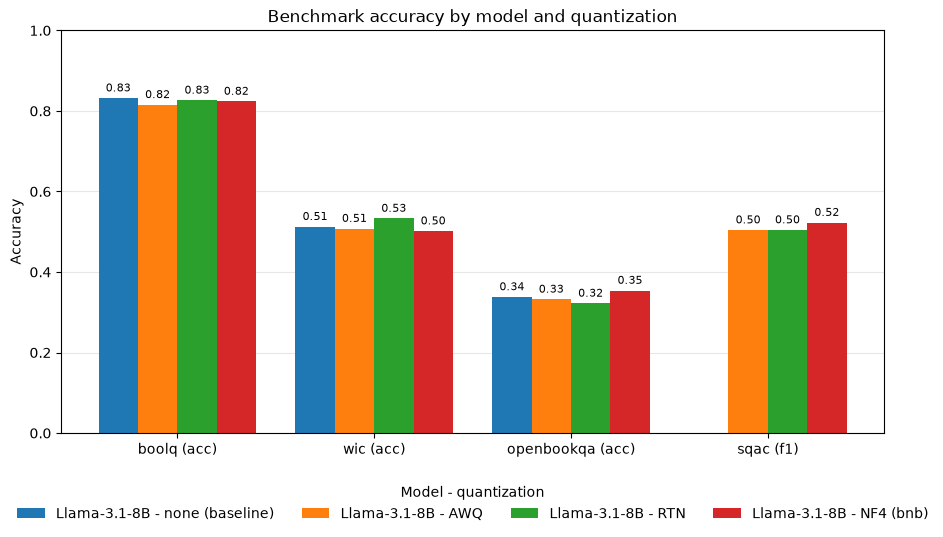

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Score columns = everything except model/quantization and the time columns
score_cols = [c for c in results_table.columns
              if c not in ("model", "quantization") and not c.endswith("_time_s")]

# "boolq_acc" -> "boolq (acc)", "sqac_f1" -> "sqac (f1)"
group_labels = [f"{c.rsplit('_', 1)[0]} ({c.rsplit('_', 1)[1]})" for c in score_cols]

n_bars = len(results_table)            # one bar per model + quantization set
x = np.arange(len(score_cols))         # one group per benchmark
width = 0.8 / n_bars
colors = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (_, row) in enumerate(results_table.iterrows()):
    label = f"{row['model']} - {row['quantization']}"
    values = row[score_cols].astype(float).values
    offset = (i - (n_bars - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=label, color=colors[i % len(colors)])

    # value on top of each bar
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}",
                    ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(group_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Benchmark accuracy by model and quantization")
ax.legend(title="Model - quantization", loc="upper center",
          bbox_to_anchor=(0.5, -0.1), ncol=n_bars, frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

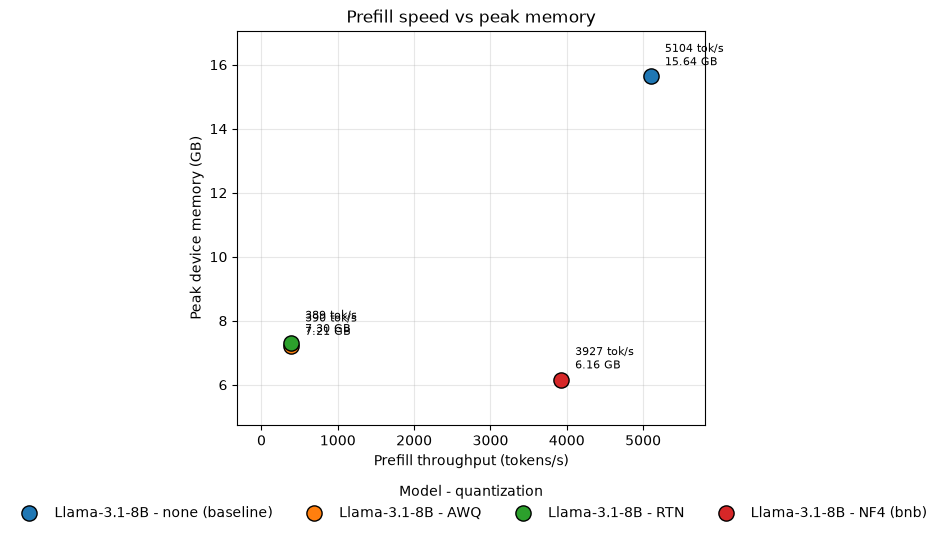

In [9]:
import matplotlib.pyplot as plt

perf_runs = [
    ("Llama-3.1-8B - none (baseline)", baseline_result["perf"]),
    ("Llama-3.1-8B - AWQ",             awq_result["perf"]),
    ("Llama-3.1-8B - RTN",             rtn_result["perf"]),
    ("Llama-3.1-8B - NF4 (bnb)",       nf4_result["perf"]),
]

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(8, 5.5))

for i, (label, perf) in enumerate(perf_runs):
    x = perf["prefill_tok_per_s"]
    y = perf["perf_peak_mem_device_gb"]
    ax.scatter(x, y, s=120, color=colors[i % len(colors)], label=label,
               edgecolor="black", zorder=3)
    ax.annotate(f"{x:.0f} tok/s\n{y:.2f} GB", (x, y),
                textcoords="offset points", xytext=(10, 8), fontsize=8)

ax.set_xlabel("Prefill throughput (tokens/s)")
ax.set_ylabel("Peak device memory (GB)")
ax.set_title("Prefill speed vs peak memory")
ax.margins(0.15)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Model - quantization", loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=len(perf_runs), frameon=False)

plt.tight_layout()
plt.show()